# TP1

Este trabajo práctico tiene dos partes. En la primera implementamos el algoritmo White Patch para corregir las diferencias de color que introduce la iluminación sobre una escena. En la segunda leemos dos imágenes en escala de grises, calculamos sus histogramas y analizamos qué información aportan.

# Autores
- Celeste Corominas
- Christian Yanez
## 27Co2026

In [1]:
%matplotlib inline

import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

## Parte 1: algoritmo White Patch

El color de la luz que ilumina una escena cambia los colores que vemos reflejados en los objetos. Una foto tomada bajo una luz rojiza se ve más roja de lo que debería. El algoritmo White Patch intenta corregir ese efecto. La idea es suponer que en la escena hay algo blanco y que los valores más altos de cada canal corresponden a ese blanco visto bajo la luz de la escena. Los máximos se buscan en cada canal por separado, así que pueden venir de píxeles distintos.

Para cada canal se calcula su valor máximo y se multiplica todo el canal por 255 dividido ese máximo. Así el máximo de cada canal queda en 255 y la imagen recupera el equilibrio de color.

In [2]:
def white_patch(img):
    # OpenCV carga las imagenes en el orden BGR, por eso el canal 0 es azul, el 1 es verde y el 2 es rojo.
    img = img.astype(np.float32)
    b_max = img[:, :, 0].max()
    g_max = img[:, :, 1].max()
    r_max = img[:, :, 2].max()
    img[:, :, 0] = img[:, :, 0] * (255.0 / b_max)
    img[:, :, 1] = img[:, :, 1] * (255.0 / g_max)
    img[:, :, 2] = img[:, :, 2] * (255.0 / r_max)
    img = np.clip(img, 0, 255)
    return img.astype(np.uint8)

Trabajamos con las ocho imágenes de la carpeta white_patch. Las cinco primeras muestran la misma escena, una figura iluminada con luz rojiza, verdosa o azulada. Las tres últimas (test_) son fotos de manos con una dominante de color más suave. Las leemos con OpenCV, les aplicamos la corrección y mostramos la imagen original junto a la corregida. Como OpenCV carga en BGR y matplotlib muestra en RGB, convertimos el orden de los canales antes de graficar.

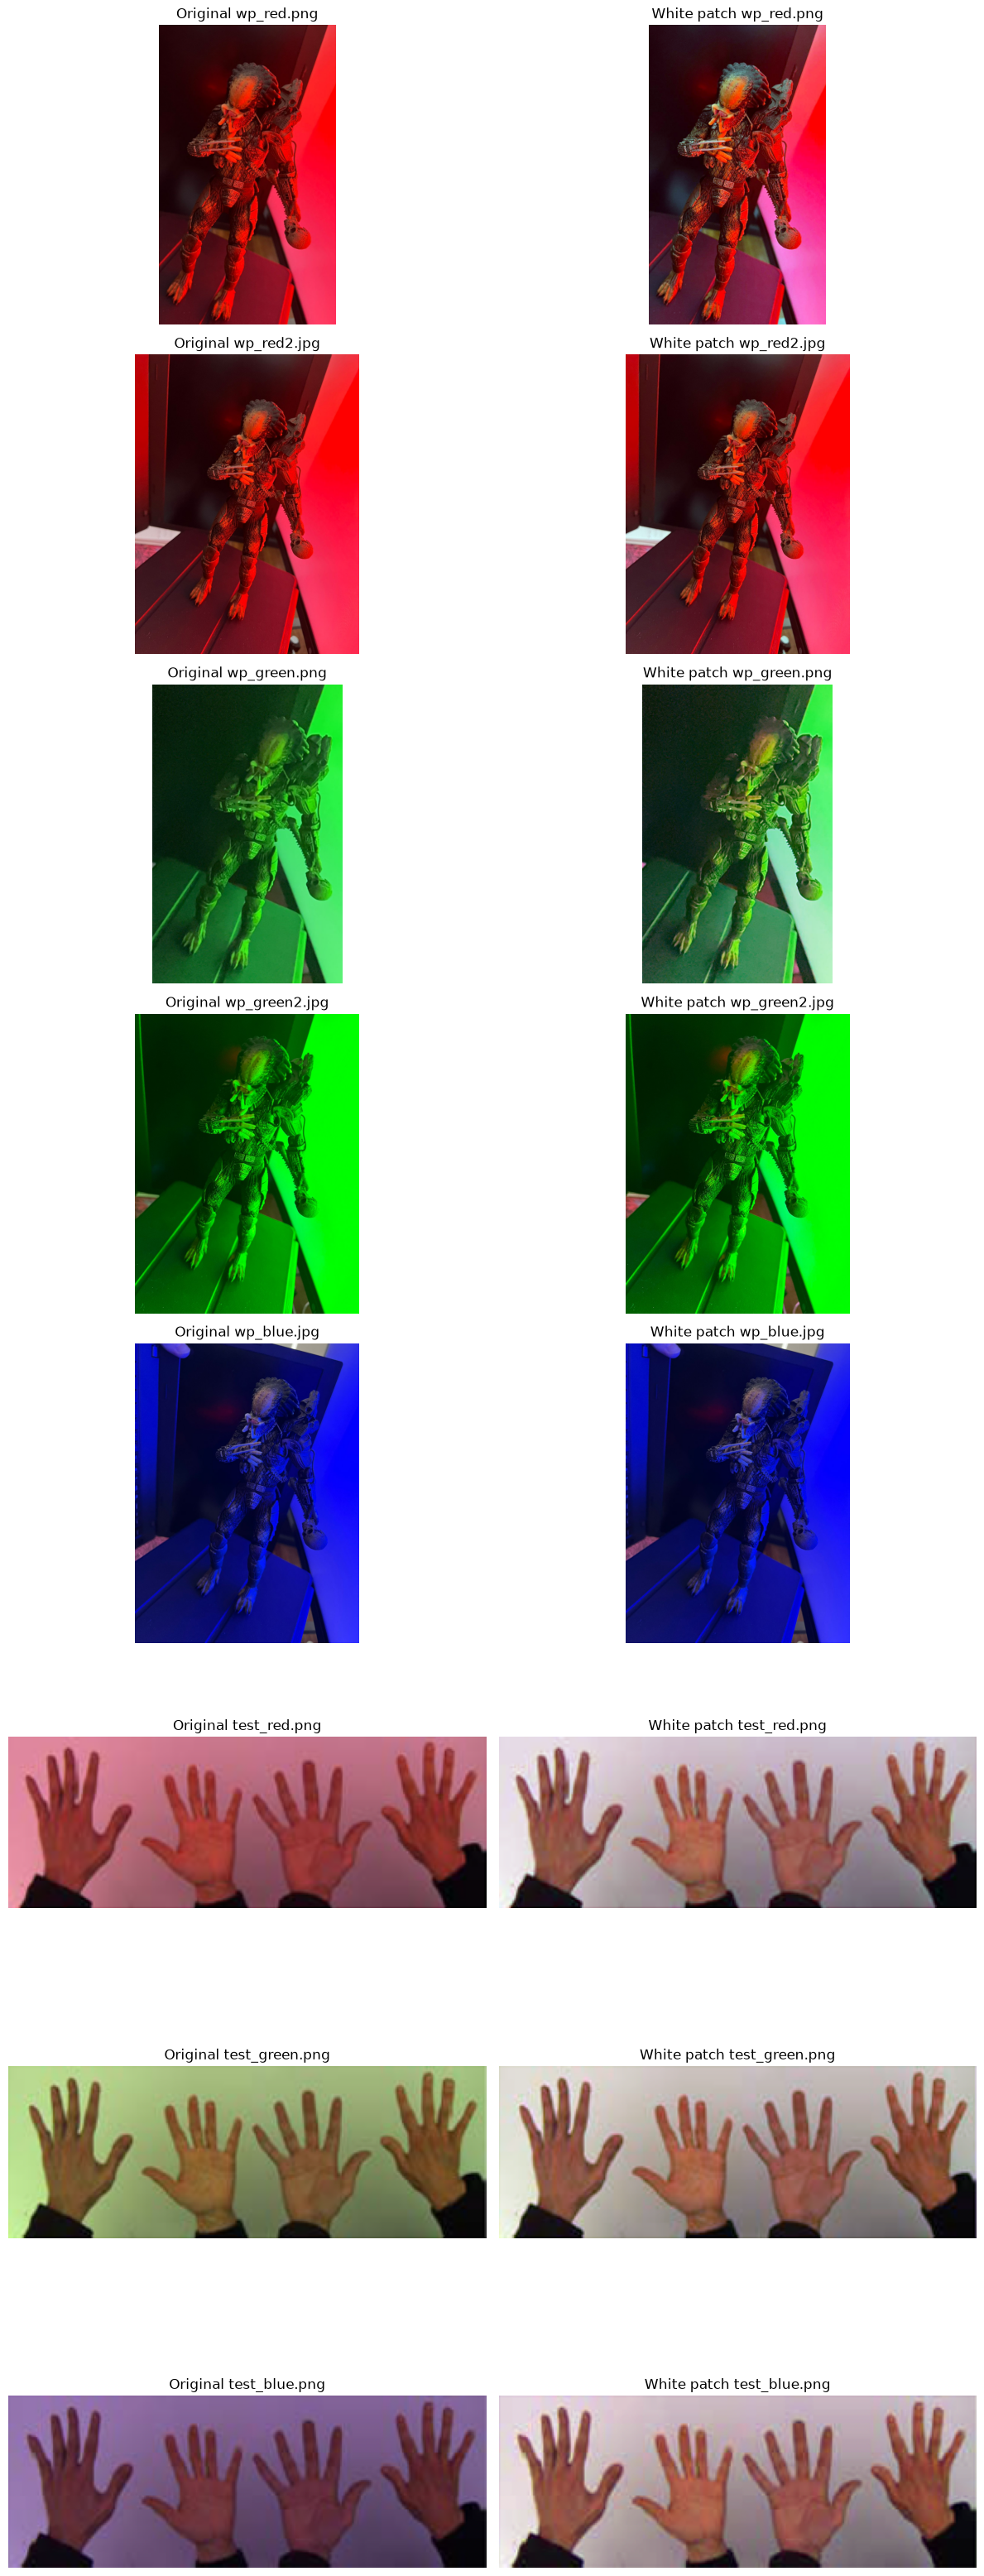

In [3]:
nombres = ['wp_red.png', 'wp_red2.jpg', 'wp_green.png', 'wp_green2.jpg', 'wp_blue.jpg',
           'test_red.png', 'test_green.png', 'test_blue.png']

plt.figure(figsize=(12, 4 * len(nombres)))

for i, nombre in enumerate(nombres):
    img = cv.imread('white_patch/' + nombre, cv.IMREAD_COLOR)
    corregida = white_patch(img)

    plt.subplot(len(nombres), 2, 2 * i + 1)
    plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title('Original ' + nombre)
    plt.axis('off')

    plt.subplot(len(nombres), 2, 2 * i + 2)
    plt.imshow(cv.cvtColor(corregida, cv.COLOR_BGR2RGB))
    plt.title('White patch ' + nombre)
    plt.axis('off')

plt.tight_layout()
plt.show()

En las imágenes corregidas se observa que el algoritmo funciona bien cuando la dominante de color es suave y ningún canal está saturado, como en las tres fotos test_. Ahí el fondo pasa a verse casi blanco y las manos recuperan un tono de piel natural. En wp_green.png también se nota una mejora clara.

En las fotos con iluminación intensa el resultado es más pobre. En wp_green2.jpg los canales rojo y azul tenían un máximo cercano a 170 y la corrección los estira hasta 255, con lo que la imagen gana algo de equilibrio pero no llega a verse neutra. En las fotos rojizas el cambio es leve y en la azulada casi no se nota ningún cambio.

Esto deja ver los puntos débiles del método. El primero es que supone que lo más brillante de cada canal corresponde a algo blanco, pero muchas veces pertenece a un objeto de color saturado o a un reflejo. Cuando eso ocurre la corrección parte de un dato equivocado y genera colores falsos. El segundo es que depende de un único valor extremo. En la imagen azulada los tres canales tienen algunos píxeles que llegan a 255 (reflejos o zonas muy brillantes, apenas decenas de píxeles en los canales verde y rojo). Como el algoritmo toma el máximo, esos pocos puntos alcanzan para que el factor de escala sea 1 y la imagen queda igual. El tercero es que amplifica el ruido de los canales más oscuros, ya que los multiplica por un factor grande. Por último es un método global, supone una sola iluminación en toda la imagen y no responde bien cuando la escena tiene luces de distinto color en zonas diferentes.

### Mejora posible: usar un percentil en lugar del máximo

El percentil 99 de un canal es el valor que deja por debajo al 99 % de los píxeles. Si ordenamos todos los valores del canal de menor a mayor, es el valor que aparece casi al final, sin contar el 1 % más brillante. A diferencia del máximo, no cambia si hay unos pocos píxeles muy brillantes, por eso representa mejor la luz de la escena.

La única diferencia con la función anterior es que el valor de referencia de cada canal se calcula con `np.percentile` en lugar de `.max()`. Como ahora hay píxeles que quedan por encima de la referencia, el `np.clip` es necesario para que no superen 255.

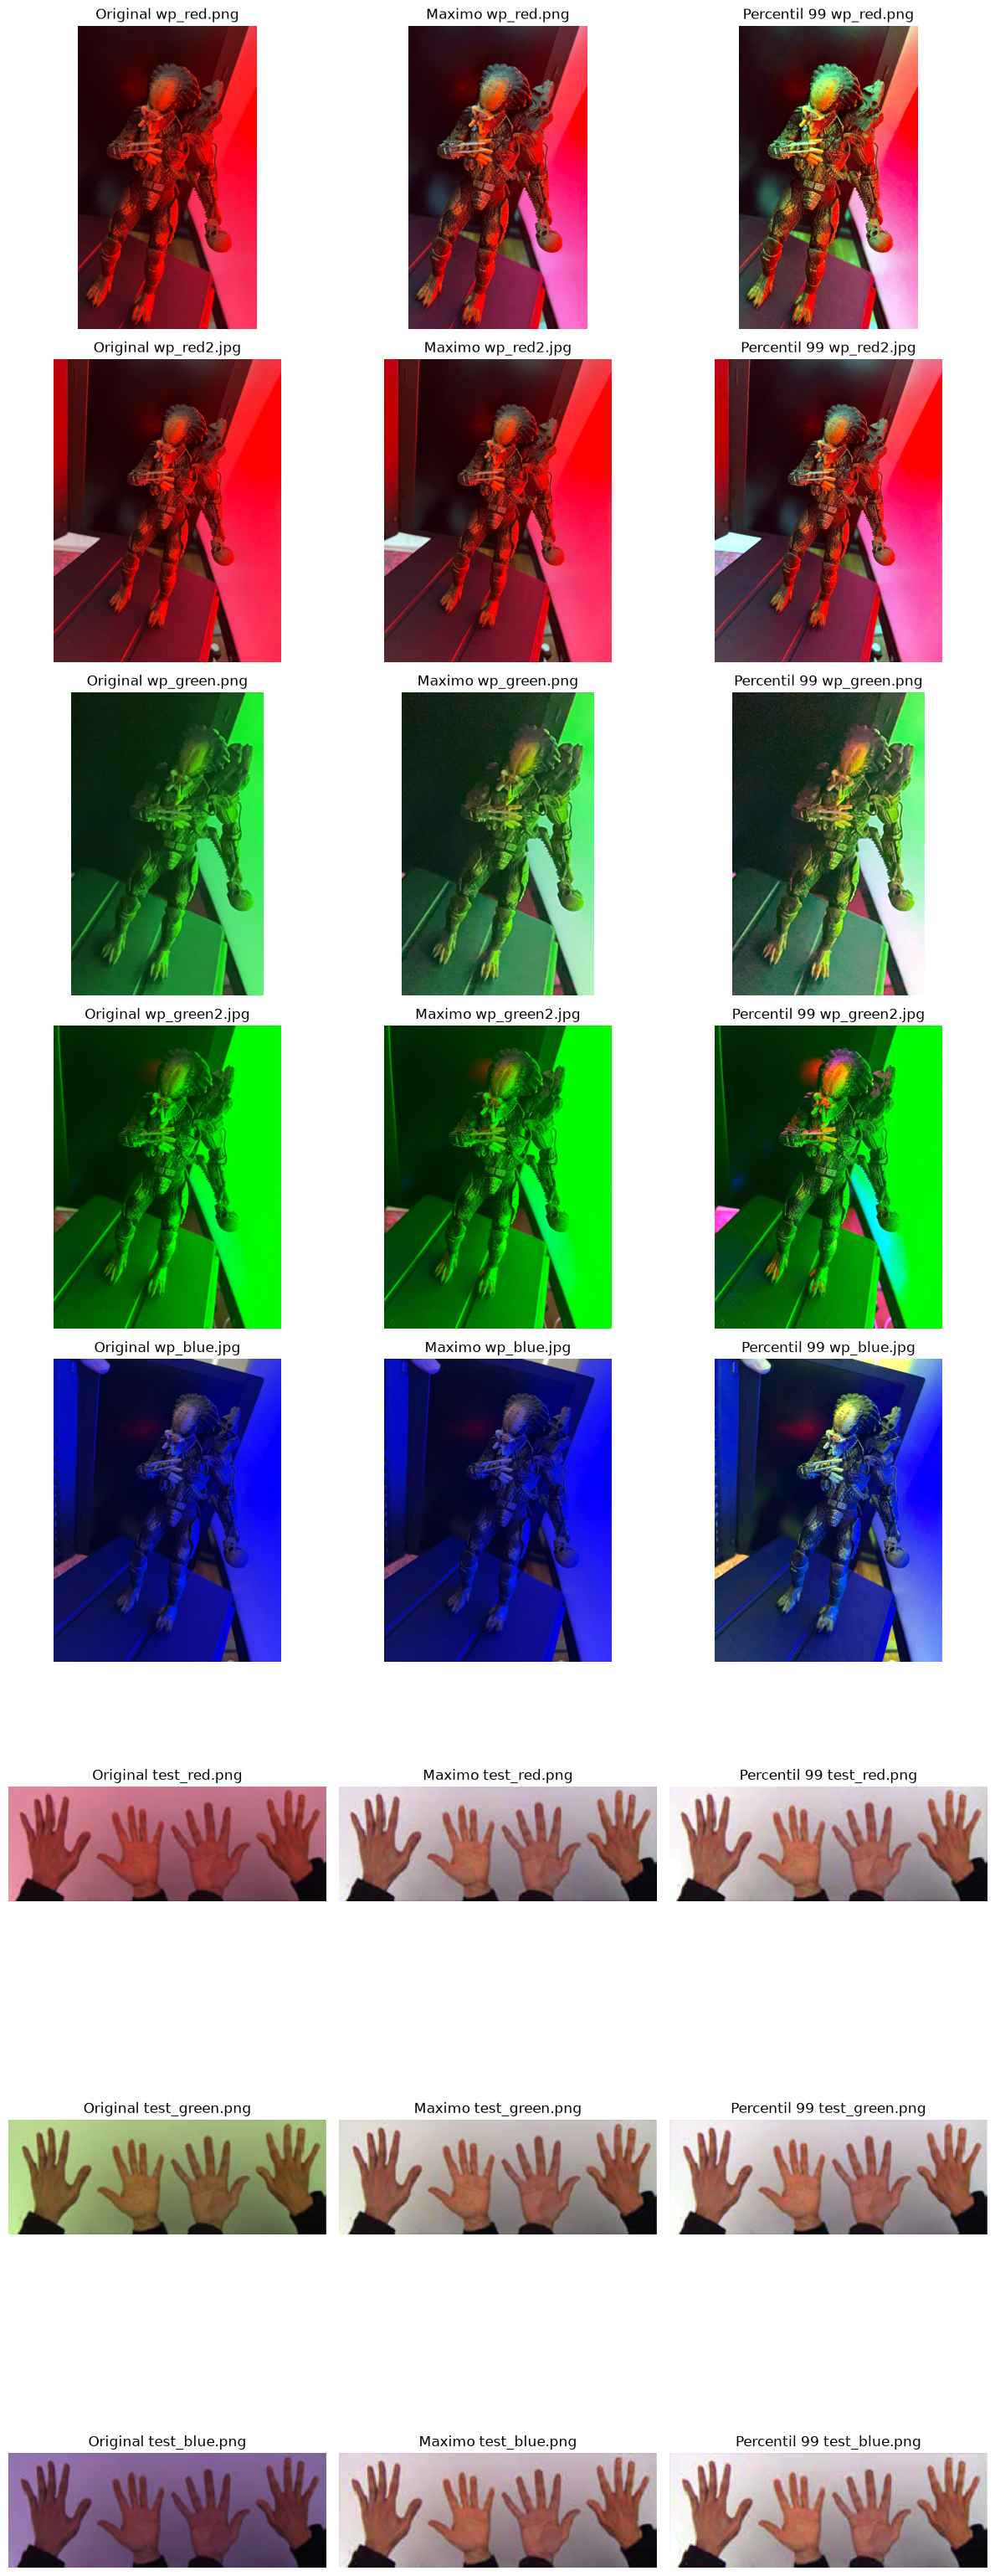

In [4]:
def white_patch_percentil(img, p=99):
    img = img.astype(np.float32)
    for c in range(3):
        ref = np.percentile(img[:, :, c], p)
        img[:, :, c] = img[:, :, c] * (255.0 / ref)
    img = np.clip(img, 0, 255)
    return img.astype(np.uint8)

plt.figure(figsize=(12, 4 * len(nombres)))

for i, nombre in enumerate(nombres):
    img = cv.imread('white_patch/' + nombre, cv.IMREAD_COLOR)
    columnas = [('Original', img), ('Maximo', white_patch(img)), ('Percentil 99', white_patch_percentil(img))]
    for j, (titulo, im) in enumerate(columnas):
        plt.subplot(len(nombres), 3, 3 * i + j + 1)
        plt.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
        plt.title(titulo + ' ' + nombre)
        plt.axis('off')

plt.tight_layout()
plt.show()

Con el percentil la diferencia más clara aparece en la imagen azulada (wp_blue.jpg). Con el máximo no cambiaba nada, y ahora la figura recupera tonos más cercanos a los reales. En las fotos test_ el resultado es casi igual al del máximo, porque ahí no había píxeles extremos que molestaran. El costo es que el 1 % de píxeles más brillantes queda recortado en 255, por eso las zonas muy iluminadas, como la pared del fondo, se ven quemadas.

En las fotos con luz muy intensa de un solo color, como wp_green2.jpg y wp_red.png, aparecen colores falsos (manchas magenta y celestes en la verdosa, tonos verdosos en la rojiza). Los canales que casi no reciben luz tienen muy poca información, y al multiplicarlos por un factor grande se amplifica sobre todo el ruido. Esto muestra que el percentil reduce el problema de los píxeles aislados, pero ninguna de las dos variantes puede corregir una iluminación casi de un solo color.

## Parte 2: histogramas

Un histograma cuenta cuántos píxeles hay para cada nivel de intensidad. Es una forma resumida de ver cómo se distribuyen los tonos de gris en una imagen. En esta parte leemos dos imágenes en escala de grises, las mostramos y comparamos sus histogramas.

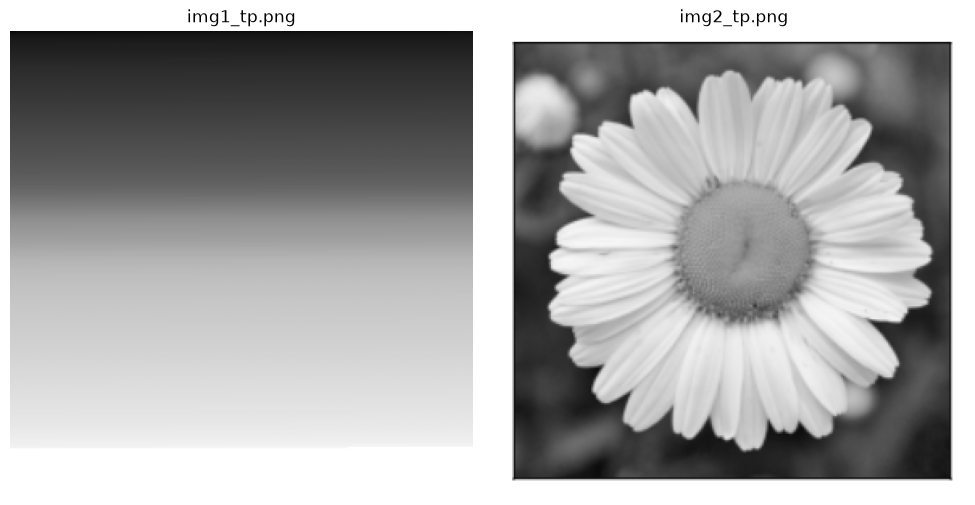

In [5]:
img1 = cv.imread('img1_tp.png', cv.IMREAD_GRAYSCALE)
img2 = cv.imread('img2_tp.png', cv.IMREAD_GRAYSCALE)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img1, cmap='gray', vmin=0, vmax=255)
plt.title('img1_tp.png')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img2, cmap='gray', vmin=0, vmax=255)
plt.title('img2_tp.png')
plt.axis('off')

plt.tight_layout()
plt.show()

Para graficar los histogramas elegimos 256 bins, uno por cada nivel de gris posible. Así se ve la distribución completa sin perder detalle.

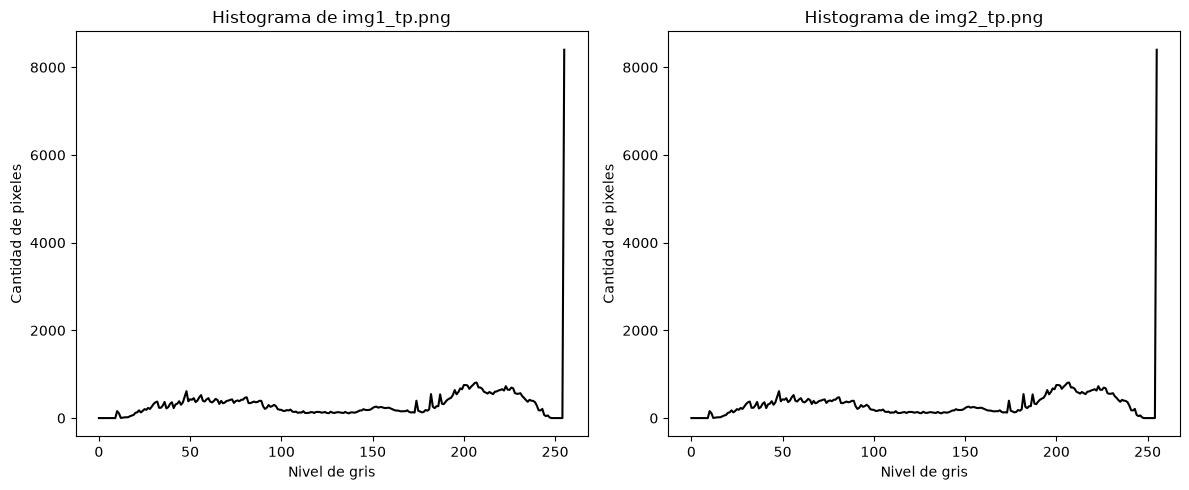

In [6]:
hist1 = cv.calcHist([img1], [0], None, [256], [0, 256])
hist2 = cv.calcHist([img2], [0], None, [256], [0, 256])

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(hist1, color='black')
plt.title('Histograma de img1_tp.png')
plt.xlabel('Nivel de gris')
plt.ylabel('Cantidad de pixeles')

plt.subplot(1, 2, 2)
plt.plot(hist2, color='black')
plt.title('Histograma de img2_tp.png')
plt.xlabel('Nivel de gris')
plt.ylabel('Cantidad de pixeles')

plt.tight_layout()
plt.show()

In [7]:
print('Histogramas identicos:', np.array_equal(hist1, hist2))

for nombre, img in [('img1_tp.png', img1), ('img2_tp.png', img2)]:
    print(nombre, '- media:', round(img.mean(), 1), '- minimo:', img.min(), '- maximo:', img.max())

Histogramas identicos: True
img1_tp.png - media: 154.8 - minimo: 2 - maximo: 255
img2_tp.png - media: 154.8 - minimo: 2 - maximo: 255


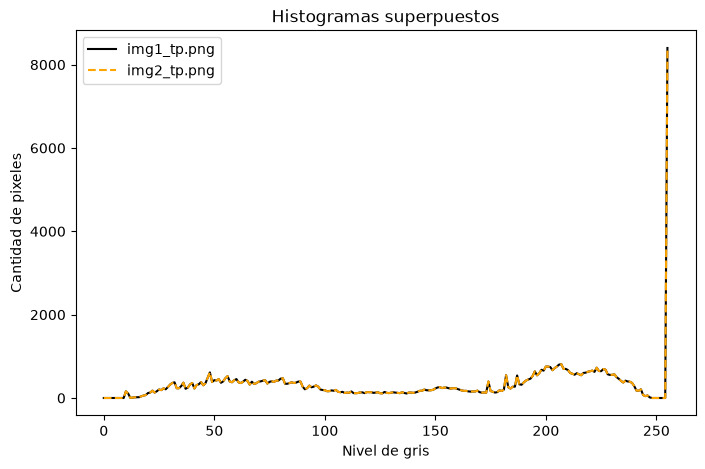

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(hist1, color='black', label='img1_tp.png')
plt.plot(hist2, color='orange', linestyle='--', label='img2_tp.png')
plt.xlabel('Nivel de gris')
plt.ylabel('Cantidad de pixeles')
plt.title('Histogramas superpuestos')
plt.legend()
plt.show()

A simple vista las dos imágenes no se parecen en nada. La primera es un degradado que va de oscuro arriba a claro abajo, con una franja blanca en la parte inferior. La segunda es la foto de una margarita, con pétalos claros, el centro gris y un fondo oscuro desenfocado. Sin embargo sus histogramas son idénticos, como confirma la comparación con `np.array_equal`: tienen la misma cantidad de píxeles en cada nivel de gris y también la misma media, el mismo mínimo y el mismo máximo. En el gráfico superpuesto las dos curvas coinciden por completo, por eso solo se distingue una.

Se probó con otros valores de bins para contrastar y el resultado siguió siendo el mismo (histogramas idénticos).

En base a los resultados anteriores podemos decir que para detección el histograma no es útil, ya que según el ejemplo podría clasificar una imagen de ruido como una de margarita.

Fin!
Saludos!